<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/Self_Supervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab: Comparing Three Models on Image Classification + DINOv2 Detection
**Duration:** ~150–180 minutes (or two sessions) | **Runtime:** Google Colab GPU recommended | **Framework:** PyTorch

### Learning objectives
1. Compare **three ways to classify images** on the *same CIFAR-10 train/test examples*:
   - **Model A — DINOv2:** use a pretrained model as a *frozen feature extractor*; train only a linear classifier.
   - **Model B — ImageNet-pretrained ResNet-18:** *transfer learning* by fine-tuning the model on CIFAR-10.
   - **Model C — Randomly initialized ResNet-18:** learn on CIFAR-10 *from scratch*.
2. Report test accuracy and training time, and discuss why pretraining helps when labeled data are limited.
3. Reuse DINOv2's spatial features for an educational pedestrian localization task, as in the original lab.

> **No transformer theory required.** Today we treat DINOv2 as a prebuilt image feature extractor: `image → vector`. Students already familiar with CNNs can study the ResNet-18 models in detail. DINOv2's internal architecture can be introduced in a later lecture.
>
> **Important fairness note:** This is a comparison of practical learning *strategies*, not an architecture-controlled experiment. DINOv2 and ResNet-18 have different backbones, pretraining datasets/objectives, trainable parameter counts, and training costs. Report these differences rather than claiming the results isolate the effect of self-supervision.

**Detection note:** The second task is an educational pedestrian localization pipeline based on mask supervision and connected components; it is not a standard end-to-end object detector.

## 0. Installation and setup

In [ ]:
%pip -q install transformers pandas scipy matplotlib torchvision scikit-learn tqdm

In [ ]:
!unzip cifar-10-batches-py.zip -d ./data


Archive:  cifar-10-batches-py.zip
   creating: ./data/cifar-10-batches-py/
  inflating: ./data/cifar-10-batches-py/data_batch_4  
  inflating: ./data/cifar-10-batches-py/readme.html  
  inflating: ./data/cifar-10-batches-py/test_batch  
  inflating: ./data/cifar-10-batches-py/data_batch_3  
  inflating: ./data/cifar-10-batches-py/batches.meta  
  inflating: ./data/cifar-10-batches-py/data_batch_2  
  inflating: ./data/cifar-10-batches-py/data_batch_5  
  inflating: ./data/cifar-10-batches-py/data_batch_1  


In [ ]:
import os, random, zipfile, urllib.request, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from sklearn.metrics import accuracy_score, classification_report
from transformers import AutoModel
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_ID = 'facebook/dinov2-small'
SIZE = 224
BATCH = 32 if DEVICE == 'cuda' else 8
print('Running on:', DEVICE)
backbone = AutoModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
for parameter in backbone.parameters(): parameter.requires_grad_(False)
DIM = backbone.config.hidden_size
PATCH = backbone.config.patch_size
GRID = SIZE // PATCH
print('Hidden dimension:', DIM, 'Patch grid:', GRID, 'x', GRID)

# DINOv2-compatible normalization (as specified by its model preprocessing config)
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)
preprocess = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])


Running on: cuda


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Hidden dimension: 384 Patch grid: 16 x 16


## 1. DINOv2: a feature extractor
We do **not** study transformer internals yet. Think of DINOv2 as a pretrained function that converts images into useful numerical features. A global feature vector supports classification. A grid of spatial features can support localization.

For the teacher: DINOv2-S returns one global (CLS) feature of dimension 384 plus 256 spatial patch features at 224×224 input. We will show their shapes, but do not need to explain self-attention.

Background (optional): <https://huggingface.co/docs/transformers/model_doc/dinov2>

In [ ]:
example = torch.randn(2, 3, SIZE, SIZE, device=DEVICE)
with torch.inference_mode():
    output = backbone(pixel_values=example).last_hidden_state
cls_features = output[:, 0]
patch_features = output[:, 1:].reshape(2, GRID, GRID, DIM)
print('All tokens:', tuple(output.shape))
print('CLS:', tuple(cls_features.shape))
print('Patch map:', tuple(patch_features.shape))
assert output.shape == (2, 1 + GRID * GRID, DIM)

All tokens: (2, 257, 384)
CLS: (2, 384)
Patch map: (2, 16, 16, 384)


## 2. Three-model classification comparison (65–90 min)
**Dataset:** CIFAR-10 (same 3,000 labeled training images and 800 held-out test images for all three methods). **Metric:** top-1 test accuracy. We also record wall-clock training time and trainable parameters.

| Model | Initialization | What students train | What it teaches |
|---|---|---|---|
| A. DINOv2 + linear head | Self-supervised pretrained | Only a small linear layer | Frozen feature extraction |
| B. ResNet-18 pretrained | Supervised ImageNet pretrained | Entire ResNet-18 (fine-tuning) | Transfer learning |
| C. ResNet-18 scratch | Random initialization | Entire ResNet-18 | Learning without pretraining |

The first comparison uses **the same data split and label space**. For controlled ResNet pretraining ablation, compare B versus C; these two have identical architecture and differ in initialization. For practical compute balance, use a smaller learning rate for fine-tuning. Different optimization settings and pretraining exposure must be acknowledged.

Use a GPU. Set `RESNET_EPOCHS` lower for a quick demo; increase it (especially for from-scratch learning) for a meaningful final comparison.

In [ ]:
train_ds = datasets.CIFAR10('./data', train=True, download=False, transform=preprocess)
test_ds = datasets.CIFAR10('./data', train=False, download=False, transform=preprocess)
train_ids = np.random.default_rng(SEED).permutation(len(train_ds))[:3000]
test_ids = np.random.default_rng(SEED+1).permutation(len(test_ds))[:800]
train_loader = DataLoader(Subset(train_ds, train_ids), batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(Subset(test_ds, test_ids), batch_size=BATCH, shuffle=False, num_workers=2)

@torch.inference_mode()
def extract_cls(loader):
    feats, targets = [], []
    for x, y in tqdm(loader, leave=False):
        tokens = backbone(pixel_values=x.to(DEVICE)).last_hidden_state
        feats.append(tokens[:, 0].cpu())
        targets.append(y)
    return torch.cat(feats), torch.cat(targets)

X_train, y_train = extract_cls(train_loader)
X_test, y_test = extract_cls(test_loader)
print('Train features:', X_train.shape, 'Test features:', X_test.shape)
# The same train_ids/test_ids are reused below for both ResNet-18 models.

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Train features: torch.Size([3000, 384]) Test features: torch.Size([800, 384])


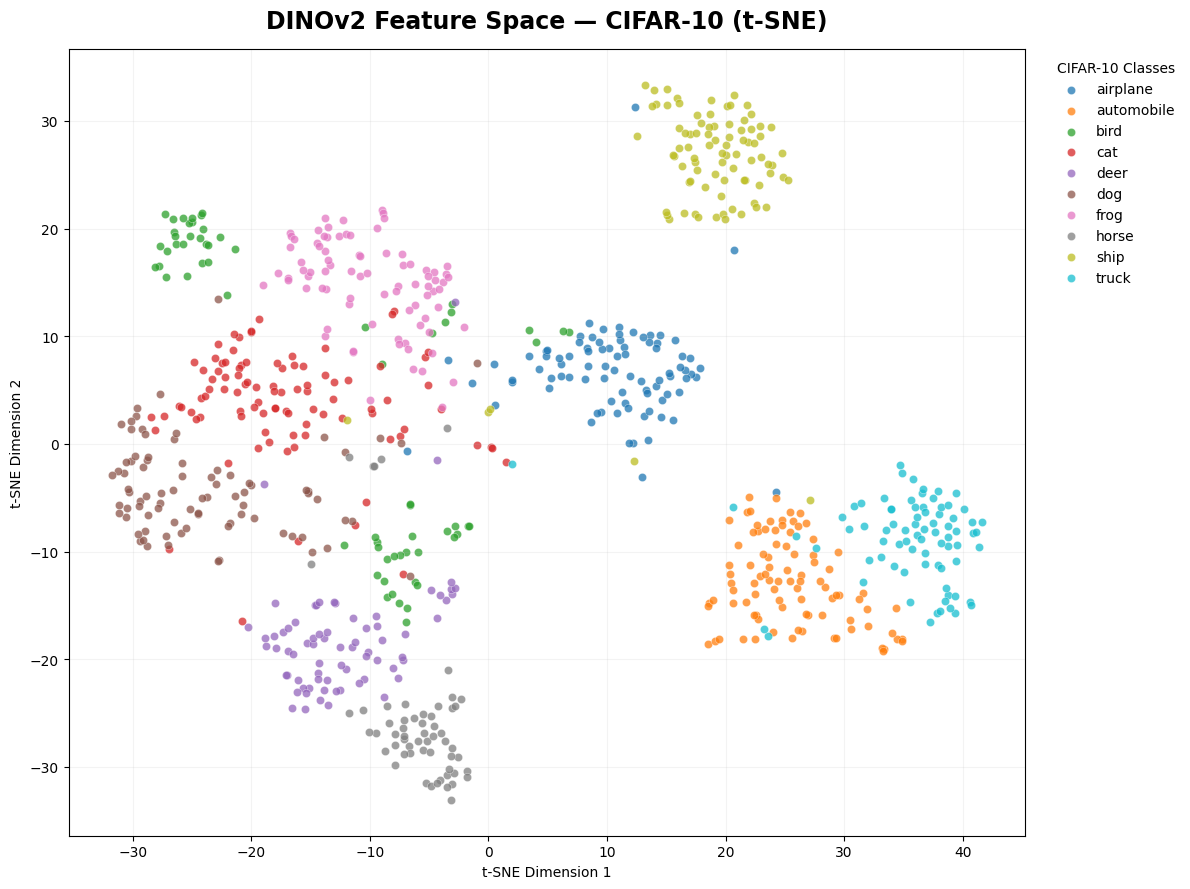

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Use the 800 test images
features = X_test.detach().cpu().numpy()
labels = y_test.detach().cpu().numpy()

# Normalize DINOv2 embeddings
features = normalize(features, norm='l2')

# PCA reduces dimensions before t-SNE
features_pca = PCA(n_components=50, random_state=42).fit_transform(features)

# Reduce to 2D using t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    max_iter=1000,
    random_state=42
)

embeddings_2d = tsne.fit_transform(features_pca)

# Plot
plt.figure(figsize=(12, 9))
colors = plt.cm.tab10(np.arange(10))

for i, name in enumerate(class_names):
    mask = labels == i
    plt.scatter(
        embeddings_2d[mask, 0],
        embeddings_2d[mask, 1],
        s=35,
        color=colors[i],
        alpha=0.75,
        label=name,
        edgecolors='white',
        linewidths=0.3
    )

plt.title("DINOv2 Feature Space — CIFAR-10 (t-SNE)",
          fontsize=17, fontweight='bold', pad=15)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="CIFAR-10 Classes", bbox_to_anchor=(1.02, 1),
           loc='upper left', frameon=False)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.savefig("dinov2_cifar10_tsne.png", dpi=300, bbox_inches='tight')
plt.show()

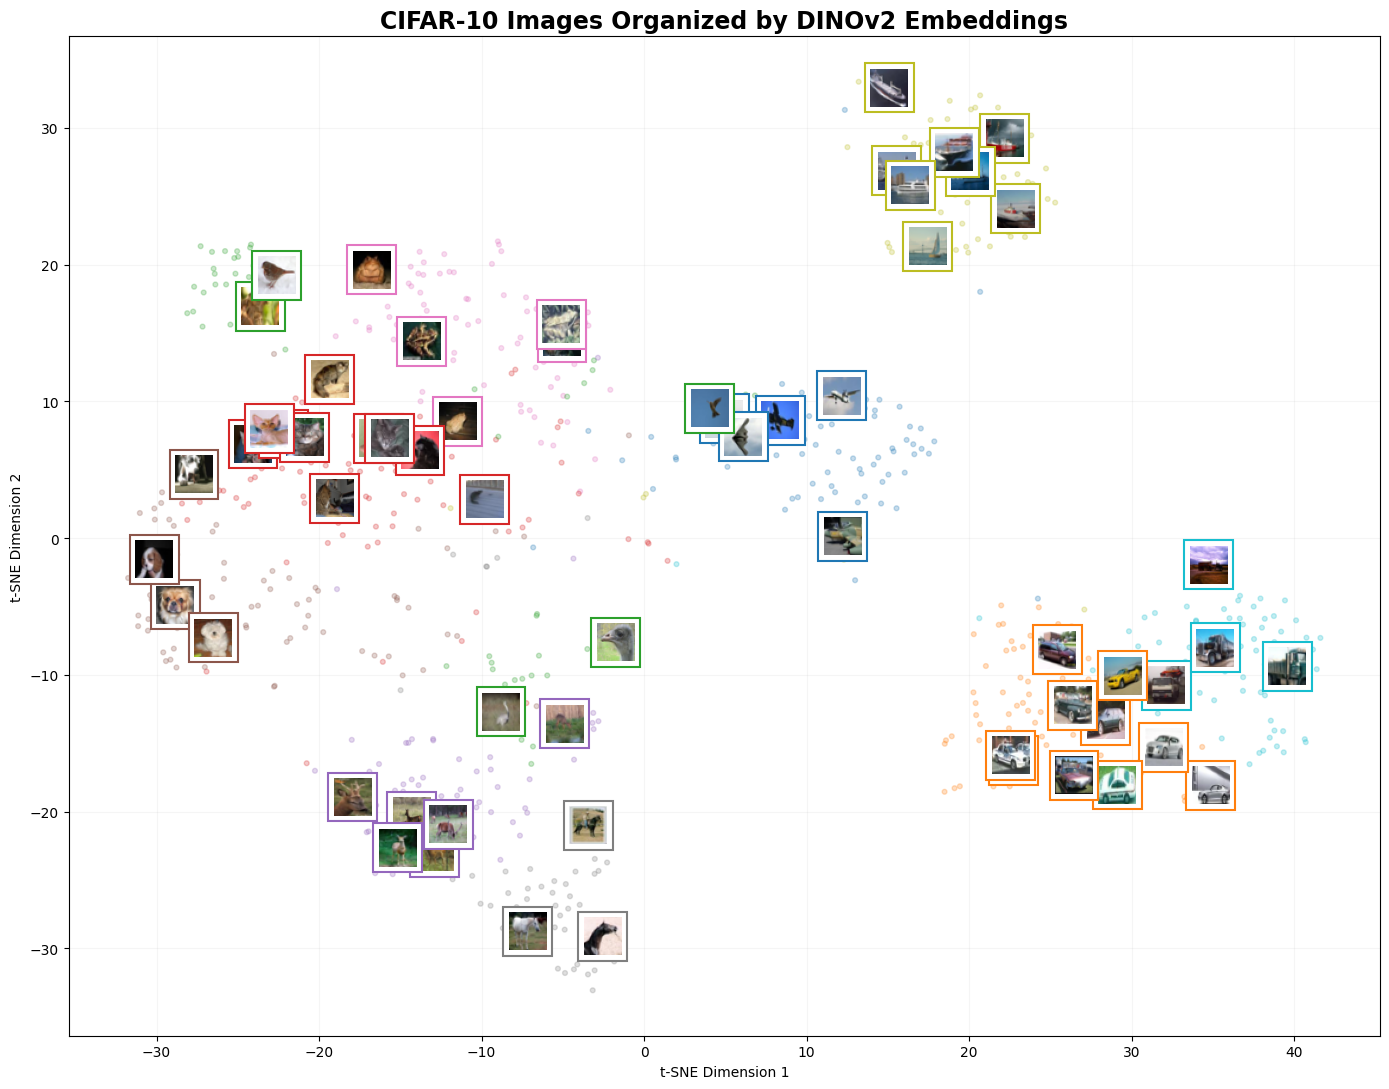

In [ ]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from torchvision import datasets

# Load original images (without transformations)
raw_test_ds = datasets.CIFAR10(
    './data', train=False, download=False
)

fig, ax = plt.subplots(figsize=(14, 11))

# Background scatter
ax.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=labels,
    cmap='tab10',
    s=12,
    alpha=0.25
)

# Select 60 images to display
rng = np.random.default_rng(42)
selected = rng.choice(len(labels), size=min(60, len(labels)), replace=False)

for idx in selected:
    original_index = int(test_ids[idx])
    image, _ = raw_test_ds[original_index]

    image_box = OffsetImage(np.asarray(image), zoom=0.85)

    ab = AnnotationBbox(
        image_box,
        (embeddings_2d[idx, 0], embeddings_2d[idx, 1]),
        frameon=True,
        bboxprops=dict(edgecolor=plt.cm.tab10(labels[idx]),
                       linewidth=1.5)
    )

    ax.add_artist(ab)

ax.set_title("CIFAR-10 Images Organized by DINOv2 Embeddings",
             fontsize=17, fontweight='bold')
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.grid(alpha=0.12)
plt.tight_layout()
plt.savefig("dinov2_tsne_images.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Model A: Frozen DINOv2 + Linear Classifier

probe = nn.Linear(X_train.shape[1], 10).to(DEVICE)
optimizer = torch.optim.AdamW(probe.parameters(), lr=1e-3)

EPOCHS = 10
BATCH_SIZE = 128

# Move features and labels to CUDA
X_train = X_train.to(DEVICE).float()
y_train = y_train.to(DEVICE).long()
X_test = X_test.to(DEVICE).float()
y_test = y_test.to(DEVICE).long()

history = {
    "train_loss": [],
    "train_acc": [],
    "test_acc": []
}

start = time.perf_counter()

for epoch in range(EPOCHS):
    probe.train()

    permutation = torch.randperm(len(X_train), device=DEVICE)

    total_loss = 0
    correct = 0
    total = 0

    for idx in permutation.split(BATCH_SIZE):
        logits = probe(X_train[idx])
        loss = F.cross_entropy(logits, y_train[idx])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(idx)
        correct += (logits.argmax(1) == y_train[idx]).sum().item()
        total += len(idx)

    train_loss = total_loss / total
    train_acc = correct / total

    # Evaluate after every epoch
    probe.eval()
    with torch.inference_mode():
        test_logits = probe(X_test)
        test_acc = (
            test_logits.argmax(1) == y_test
        ).float().mean().item()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Test Acc: {test_acc:.2%}"
    )

dino_head_seconds = time.perf_counter() - start
dino_accuracy = history["test_acc"][-1]

Epoch [01/10] | Loss: 1.4477 | Train Acc: 53.83% | Test Acc: 85.62%
Epoch [02/10] | Loss: 0.3460 | Train Acc: 89.57% | Test Acc: 93.00%
Epoch [03/10] | Loss: 0.2265 | Train Acc: 93.17% | Test Acc: 94.00%
Epoch [04/10] | Loss: 0.1826 | Train Acc: 94.83% | Test Acc: 94.50%
Epoch [05/10] | Loss: 0.1528 | Train Acc: 95.60% | Test Acc: 94.62%
Epoch [06/10] | Loss: 0.1324 | Train Acc: 96.53% | Test Acc: 95.00%
Epoch [07/10] | Loss: 0.1155 | Train Acc: 97.17% | Test Acc: 95.00%
Epoch [08/10] | Loss: 0.1023 | Train Acc: 97.73% | Test Acc: 95.00%
Epoch [09/10] | Loss: 0.0923 | Train Acc: 98.03% | Test Acc: 94.50%
Epoch [10/10] | Loss: 0.0831 | Train Acc: 98.43% | Test Acc: 94.75%


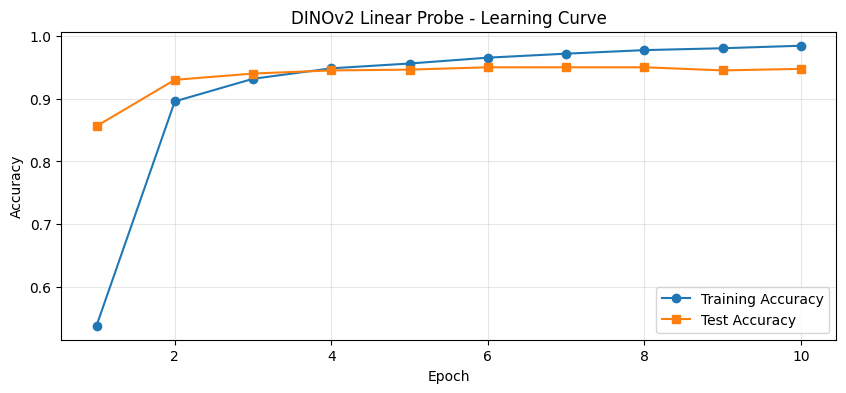

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs,
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["test_acc"],
    marker="s",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DINOv2 Linear Probe - Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

probe.eval()

with torch.inference_mode():
    dino_pred = probe(X_test.to(DEVICE)).argmax(1).cpu().numpy()

y_true = y_test.cpu().numpy()

dino_accuracy = accuracy_score(y_true, dino_pred)

print(f'Model A (DINOv2 frozen + linear head): {dino_accuracy:.3%}')
print(f'Linear-head training time: {dino_head_seconds:.1f}s')

print(classification_report(
    y_true,
    dino_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

Model A (DINOv2 frozen + linear head): 94.750%
Linear-head training time: 0.3s
              precision    recall  f1-score   support

    airplane       0.94      0.95      0.95        86
  automobile       0.95      0.98      0.96        92
        bird       0.91      0.94      0.92        65
         cat       0.94      0.85      0.90        95
        deer       0.96      0.99      0.97        72
         dog       0.93      0.93      0.93        83
        frog       0.94      0.96      0.95        83
       horse       0.97      1.00      0.98        58
        ship       0.98      0.97      0.97        88
       truck       0.96      0.94      0.95        78

    accuracy                           0.95       800
   macro avg       0.95      0.95      0.95       800
weighted avg       0.95      0.95      0.95       800



### 2.2 Model B and Model C: ResNet-18 transfer learning versus learning from scratch
Both ResNet-18 models use the same network, input preprocessing, training images and test images. **Only the initialization and learning rate differ.** We replace the final classification layer with a 10-class layer. Fine-tuning updates all of ResNet-18's parameters; training from scratch also updates all parameters.

For a quick classroom demonstration, both run for 8 epochs. **Scratch training may need substantially more epochs** to converge; avoid presenting an early difference as the best achievable scratch-model performance.

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as tv_models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

resnet_preprocess = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

resnet_train_ds = datasets.CIFAR10('./data', train=True, download=False, transform=resnet_preprocess)
resnet_test_ds = datasets.CIFAR10('./data', train=False, download=False, transform=resnet_preprocess)

resnet_train_loader = DataLoader(
    Subset(resnet_train_ds, train_ids.tolist()),
    batch_size=BATCH, shuffle=True, num_workers=2
)
resnet_test_loader = DataLoader(
    Subset(resnet_test_ds, test_ids.tolist()),
    batch_size=BATCH, shuffle=False, num_workers=2
)

def build_resnet(pretrained=True, freeze_backbone=False):
    weights = tv_models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    net = tv_models.resnet18(weights=weights)
    if freeze_backbone:
        for param in net.parameters():
            param.requires_grad = False
    net.fc = nn.Linear(net.fc.in_features, 10)
    return net.to(DEVICE)

resnet_pretrained = build_resnet(pretrained=True, freeze_backbone=True)
resnet_scratch = build_resnet(pretrained=False, freeze_backbone=False)

for name, net in [
    ("Pretrained ResNet-18", resnet_pretrained),
    ("Scratch ResNet-18", resnet_scratch)
]:
    trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
    print(f"{name}: {trainable:,} trainable parameters")

print("DINOv2 linear head:",
      f"{sum(p.numel() for p in probe.parameters() if p.requires_grad):,}")

Pretrained ResNet-18: 5,130 trainable parameters
Scratch ResNet-18: 11,181,642 trainable parameters
DINOv2 linear head: 3,850


In [ ]:
RESNET_EPOCHS = 10

def train_resnet(net, train_loader, epochs, lr, label, freeze_backbone=False):

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, net.parameters()),
        lr=lr,
        weight_decay=1e-4
    )

    history = []
    start = time.perf_counter()

    for epoch in range(epochs):

        if freeze_backbone:
            net.eval()       # Keep frozen BatchNorm statistics fixed
            net.fc.train()   # Train classification head
        else:
            net.train()

        total_correct = 0
        total_count = 0
        total_loss = 0.0

        for x, y in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = net(x)
            loss = F.cross_entropy(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_correct += (logits.argmax(1) == y).sum().item()
            total_count += len(y)
            total_loss += loss.item() * len(y)

        history.append({
            'epoch': epoch + 1,
            'train_loss': total_loss / total_count,
            'train_accuracy': total_correct / total_count
        })

        print(
            f'{label} | Epoch {epoch+1}/{epochs} | '
            f'Loss: {history[-1]["train_loss"]:.4f} | '
            f'Accuracy: {history[-1]["train_accuracy"]:.2%}'
        )

    return history, time.perf_counter() - start


@torch.inference_mode()
def evaluate_resnet(net, loader):
    net.eval()
    predictions, targets = [], []
    for x, y in loader:
        predictions.append(net(x.to(DEVICE)).argmax(1).cpu())
        targets.append(y)
    return accuracy_score(torch.cat(targets).numpy(), torch.cat(predictions).numpy())

In [ ]:
pretrained_history, pretrained_seconds = train_resnet(
    resnet_pretrained,
    resnet_train_loader,
    epochs=RESNET_EPOCHS,
    lr=1e-3,
    label="Pretrained ResNet-18",
    freeze_backbone=True
)

pretrained_accuracy = evaluate_resnet(
    resnet_pretrained,
    resnet_test_loader
)

print(f"Model B Accuracy: {pretrained_accuracy:.2%}")

Pretrained ResNet-18 | Epoch 1/10 | Loss: 1.3013 | Accuracy: 60.17%
Pretrained ResNet-18 | Epoch 2/10 | Loss: 0.6639 | Accuracy: 81.43%
Pretrained ResNet-18 | Epoch 3/10 | Loss: 0.5317 | Accuracy: 84.63%
Pretrained ResNet-18 | Epoch 4/10 | Loss: 0.4723 | Accuracy: 85.87%
Pretrained ResNet-18 | Epoch 5/10 | Loss: 0.4257 | Accuracy: 87.40%
Pretrained ResNet-18 | Epoch 6/10 | Loss: 0.3917 | Accuracy: 88.53%
Pretrained ResNet-18 | Epoch 7/10 | Loss: 0.3646 | Accuracy: 89.70%
Pretrained ResNet-18 | Epoch 8/10 | Loss: 0.3438 | Accuracy: 89.57%
Pretrained ResNet-18 | Epoch 9/10 | Loss: 0.3285 | Accuracy: 90.17%
Pretrained ResNet-18 | Epoch 10/10 | Loss: 0.3105 | Accuracy: 90.97%
Model B Accuracy: 86.62%


In [ ]:
for param in resnet_scratch.parameters():
    param.requires_grad = True

scratch_history, scratch_seconds = train_resnet(
    resnet_scratch,
    resnet_train_loader,
    epochs=RESNET_EPOCHS,
    lr=1e-3,
    label="ResNet-18 Scratch",
    freeze_backbone=False
)

scratch_accuracy = evaluate_resnet(
    resnet_scratch,
    resnet_test_loader
)

print(f"Model C Accuracy: {scratch_accuracy:.2%}")

ResNet-18 Scratch | Epoch 1/10 | Loss: 2.0751 | Accuracy: 24.67%
ResNet-18 Scratch | Epoch 2/10 | Loss: 1.8542 | Accuracy: 31.23%
ResNet-18 Scratch | Epoch 3/10 | Loss: 1.7344 | Accuracy: 36.30%
ResNet-18 Scratch | Epoch 4/10 | Loss: 1.6746 | Accuracy: 37.87%
ResNet-18 Scratch | Epoch 5/10 | Loss: 1.5823 | Accuracy: 41.20%
ResNet-18 Scratch | Epoch 6/10 | Loss: 1.5005 | Accuracy: 45.27%
ResNet-18 Scratch | Epoch 7/10 | Loss: 1.4576 | Accuracy: 46.07%
ResNet-18 Scratch | Epoch 8/10 | Loss: 1.3504 | Accuracy: 49.50%
ResNet-18 Scratch | Epoch 9/10 | Loss: 1.2685 | Accuracy: 53.57%
ResNet-18 Scratch | Epoch 10/10 | Loss: 1.1796 | Accuracy: 56.77%
Model C Accuracy: 46.25%


### 2.3 Compare the three models
The DINOv2 number below records **linear-head training time only**. DINOv2 feature extraction took additional time, so its displayed time is **not directly comparable** to end-to-end ResNet training. Use test accuracy for the primary comparison; discuss computational cost qualitatively.

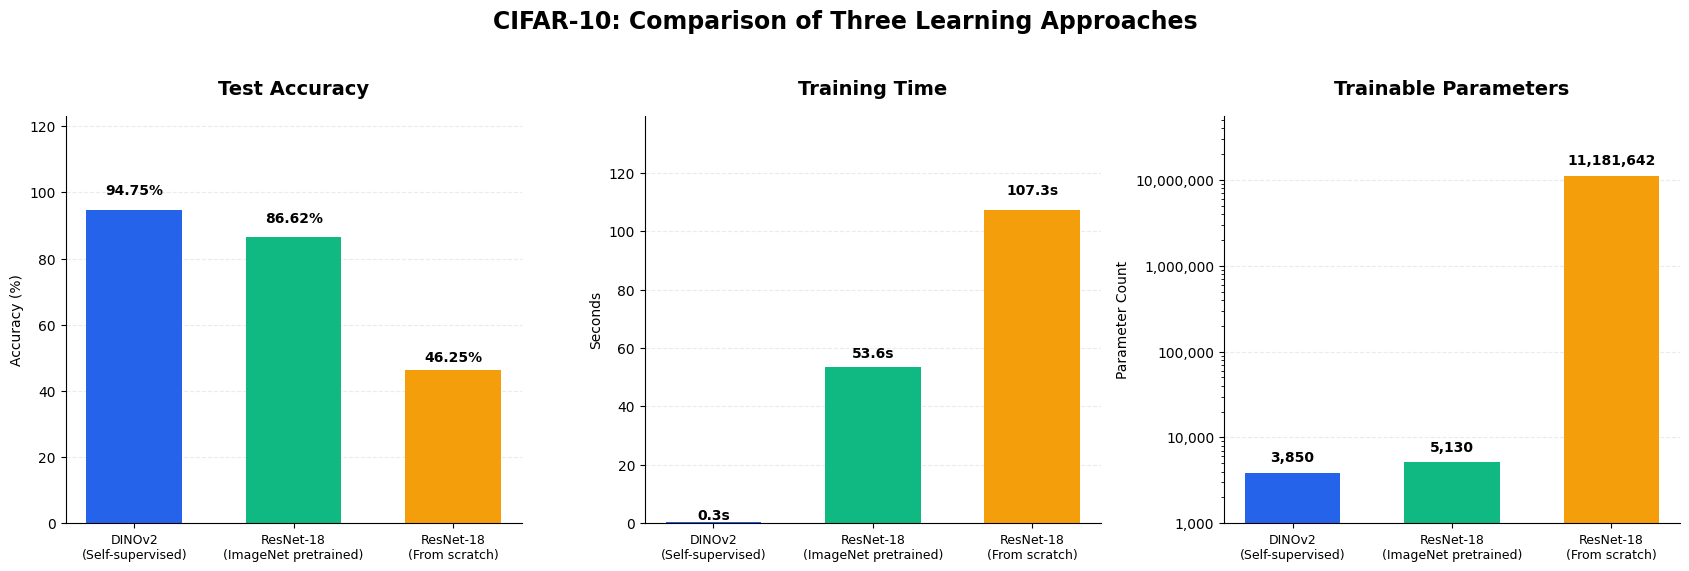

,Model,Accuracy,Time,Parameters
0,DINOv2\n(Self-supervised),94.750,0.295011,3850
1,ResNet-18\n(ImageNet pretrained),86.625,53.588790,5130
2,ResNet-18\n(From scratch),46.250,107.313805,11181642


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Recalculate results from latest trained models
results = pd.DataFrame([
    {
        "Model": "DINOv2\n(Self-supervised)",
        "Accuracy": dino_accuracy * 100,
        "Time": dino_head_seconds,
        "Parameters": sum(p.numel() for p in probe.parameters() if p.requires_grad)
    },
    {
        "Model": "ResNet-18\n(ImageNet pretrained)",
        "Accuracy": pretrained_accuracy * 100,
        "Time": pretrained_seconds,
        "Parameters": sum(p.numel() for p in resnet_pretrained.parameters() if p.requires_grad)
    },
    {
        "Model": "ResNet-18\n(From scratch)",
        "Accuracy": scratch_accuracy * 100,
        "Time": scratch_seconds,
        "Parameters": sum(p.numel() for p in resnet_scratch.parameters() if p.requires_grad)
    }
])

colors = ["#2563EB", "#10B981", "#F59E0B"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

metrics = [
    ("Accuracy", "Test Accuracy", "Accuracy (%)"),
    ("Time", "Training Time", "Seconds"),
    ("Parameters", "Trainable Parameters", "Parameter Count")
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    values = results[column].to_numpy()
    bars = ax.bar(range(3), values, color=colors, width=0.6)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(3))
    ax.set_xticklabels(results["Model"], fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    if column == "Parameters":
        ax.set_yscale("log")
        ax.set_ylim(1e3, max(values) * 5)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
    else:
        ax.set_ylim(0, max(values) * 1.3)

    for bar, value in zip(bars, values):
        if column == "Accuracy":
            label = f"{value:.2f}%"
        elif column == "Time":
            label = f"{value:.1f}s"
        else:
            label = f"{int(value):,}"

        y = value * (1.25 if column == "Parameters" else 1.04)
        ax.text(bar.get_x() + bar.get_width()/2, y, label,
                ha="center", va="bottom", fontsize=10, fontweight="bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("CIFAR-10: Comparison of Three Learning Approaches",
             fontsize=17, fontweight="bold", y=1.03)

plt.tight_layout()
plt.savefig("cifar10_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

display(results)

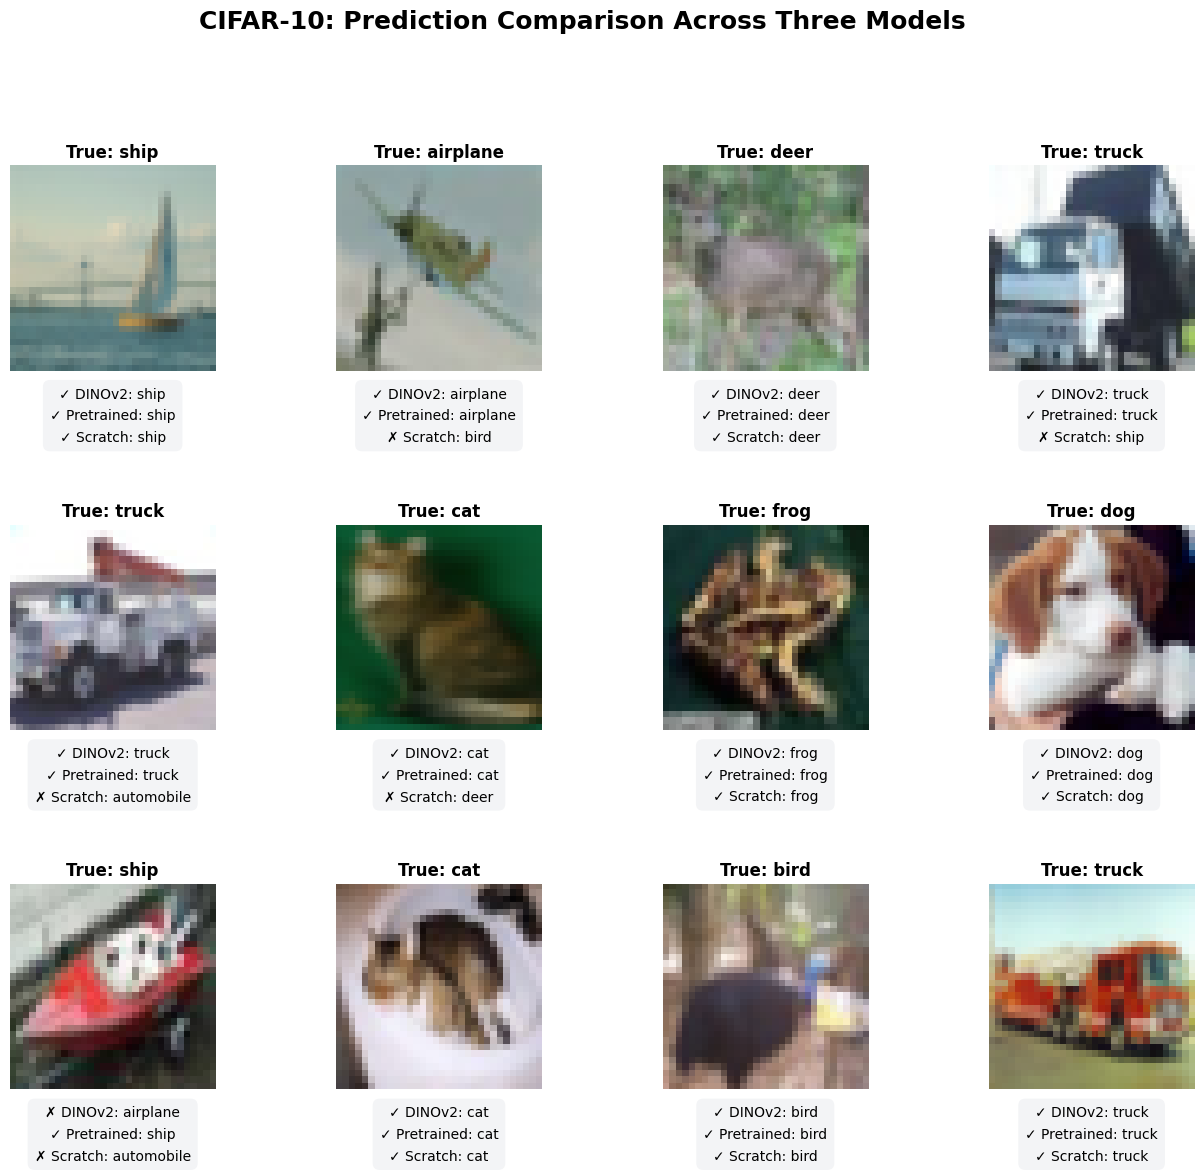

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Get original CIFAR-10 images for visualization
raw_test_ds = datasets.CIFAR10('./data', train=False, download=False)

# Predictions from DINOv2 (cached embeddings)
probe.eval()
with torch.inference_mode():
    dino_preds = probe(X_test.to(DEVICE)).argmax(1).cpu().numpy()

# Predictions from both ResNet-18 models
@torch.inference_mode()
def get_predictions(model, loader):
    model.eval()
    preds = []
    for x, _ in loader:
        preds.extend(model(x.to(DEVICE)).argmax(1).cpu().numpy())
    return np.array(preds)

resnet_pre_preds = get_predictions(resnet_pretrained, resnet_test_loader)
resnet_scratch_preds = get_predictions(resnet_scratch, resnet_test_loader)

# Select 12 reproducible test samples
rng = np.random.default_rng(42)
selected = rng.choice(len(test_ids), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, idx in zip(axes, selected):
    image, true_label = raw_test_ds[int(test_ids[idx])]

    predictions = [
        ("DINOv2", dino_preds[idx]),
        ("Pretrained", resnet_pre_preds[idx]),
        ("Scratch", resnet_scratch_preds[idx])
    ]

    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"True: {class_names[true_label]}", fontsize=12, fontweight="bold")

    prediction_text = "\n".join(
        f"{'✓' if pred == true_label else '✗'} {name}: {class_names[pred]}"
        for name, pred in predictions
    )

    ax.text(
        0.5, -0.08, prediction_text,
        transform=ax.transAxes,
        fontsize=10,
        ha="center", va="top",
        linespacing=1.7,
        bbox=dict(facecolor="#F3F4F6", edgecolor="none", boxstyle="round,pad=0.5")
    )

plt.subplots_adjust(hspace=0.75, wspace=0.25)
plt.suptitle("CIFAR-10: Prediction Comparison Across Three Models",
             fontsize=18, fontweight="bold", y=1.01)
plt.savefig("cifar10_prediction_examples.png", dpi=300, bbox_inches="tight")
plt.show()

### Discussion
1. Which method obtains the highest accuracy with only 3,000 labeled training examples?
2. Why might an ImageNet-pretrained CNN learn faster than an identical CNN with random weights?
3. Why is comparing Model B and C more controlled than comparing A and B?
4. Which method trains the fewest parameters? Does that necessarily mean the smallest total compute cost?
5. How might results change if both ResNet-18 models trained for 30 epochs or the training set increased to 30,000 images?

## 3. Detection: frozen patch tokens + pedestrian localization head
**Dataset:** Penn-Fudan Pedestrian (170 images, pedestrian instance masks). We create a **binary person / background patch label** from segmentation masks, train a lightweight head, and use connected components to obtain candidate pedestrian boxes. The task uses masks for supervision; it is therefore closer to **segmentation-assisted detection** than conventional box-only detector training.

Data source: <https://www.cis.upenn.edu/~jshi/ped_html/> and [PyTorch object detection tutorial](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html).


In [ ]:
root = Path('./data/PennFudanPed')
if not root.exists():
    archive = Path('./data/PennFudanPed.zip')
    archive.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip'
    urllib.request.urlretrieve(url, archive)
    with zipfile.ZipFile(archive) as z: z.extractall('./data')
assert (root / 'PNGImages').exists(), 'Dataset download failed. Check the PennFudanPed.zip source.'

class Pedestrians(Dataset):
    def __init__(self, root):
        self.root = Path(root)
        self.images = sorted((self.root / 'PNGImages').glob('*.png'))
    def __len__(self): return len(self.images)
    def __getitem__(self, i):
        image_path = self.images[i]
        mask_path = self.root / 'PedMasks' / image_path.name.replace('.png', '_mask.png')
        # Penn-Fudan masks correspond to filename with '_mask' suffix
        image = Image.open(image_path).convert('RGB').resize((SIZE, SIZE))
        mask = Image.open(mask_path).resize((SIZE, SIZE), resample=Image.Resampling.NEAREST)
        image_tensor = TF.normalize(TF.to_tensor(image), MEAN, STD)
        # Mask IDs indicate distinct pedestrians; 0 = background
        target = (torch.as_tensor(np.array(mask).copy()) > 0).float()[None]
        # Average foreground occupancy per patch gives soft supervision
        patch_target = F.avg_pool2d(target[None], kernel_size=PATCH, stride=PATCH)[0, 0]
        return image_tensor, patch_target, target[0]

ped_ds = Pedestrians(root)
indices = np.random.default_rng(SEED).permutation(len(ped_ds))
train_ped = Subset(ped_ds, indices[:135])
test_ped = Subset(ped_ds, indices[135:])
print('Pedestrian training/test:', len(train_ped), len(test_ped))


Pedestrian training/test: 135 35


In [ ]:
@torch.inference_mode()
def extract_patches(dataset):
    loader = DataLoader(dataset, batch_size=BATCH, shuffle=False, num_workers=2)
    features, patch_labels, full_masks = [], [], []
    for x, patch, mask in tqdm(loader, leave=False):
        tokens = backbone(pixel_values=x.to(DEVICE)).last_hidden_state[:, 1:, :]
        features.append(tokens.reshape(-1, GRID, GRID, DIM).cpu())
        patch_labels.append(patch.cpu())
        full_masks.append(mask.cpu())
    return torch.cat(features), torch.cat(patch_labels), torch.cat(full_masks)

P_train, T_train, M_train = extract_patches(train_ped)
P_test, T_test, M_test = extract_patches(test_ped)
print('Patch features:', P_train.shape, 'Patch labels:', T_train.shape)


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Patch features: torch.Size([135, 16, 16, 384]) Patch labels: torch.Size([135, 16, 16])


In [ ]:
# CNN localization head
localizer = nn.Sequential(
    nn.Conv2d(DIM, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(128, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(64, 1, kernel_size=1)
).to(DEVICE)

optimizer = torch.optim.AdamW(localizer.parameters(), lr=1e-3)
EPOCHS = 50

for epoch in range(EPOCHS):
    localizer.train()
    perm = torch.randperm(len(P_train))
    total_loss = 0

    for idx in perm.split(16):
        x = P_train[idx].to(DEVICE).permute(0, 3, 1, 2)
        y = T_train[idx].to(DEVICE)

        logits = localizer(x).squeeze(1)
        loss = F.binary_cross_entropy_with_logits(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {total_loss:.4f}")

localizer.eval()
with torch.inference_mode():
    x_test = P_test.to(DEVICE).permute(0, 3, 1, 2)
    probs = torch.sigmoid(localizer(x_test).squeeze(1)).cpu()

pred_binary = probs >= 0.5
target_binary = T_test >= 0.5
intersection = (pred_binary & target_binary).sum().item()
union = (pred_binary | target_binary).sum().item()
print(f"Patch IoU: {intersection / max(union, 1):.3f}")

Epoch 5/50 | Loss: 1.4952
Epoch 10/50 | Loss: 1.3576
Epoch 15/50 | Loss: 1.2949
Epoch 20/50 | Loss: 1.2448
Epoch 25/50 | Loss: 1.2252
Epoch 30/50 | Loss: 1.2053
Epoch 35/50 | Loss: 1.1964
Epoch 40/50 | Loss: 1.1612
Epoch 45/50 | Loss: 1.1420
Epoch 50/50 | Loss: 1.1866
Patch IoU: 0.724


### Convert localization masks to bounding boxes
Threshold patch probabilities, upsample to image resolution, and find connected regions. Boxes are **approximate** and may merge nearby people because DINOv2 provides coarse 16×16 spatial tokens at 224 resolution. This approach does not predict identities or separate all overlapping instances.

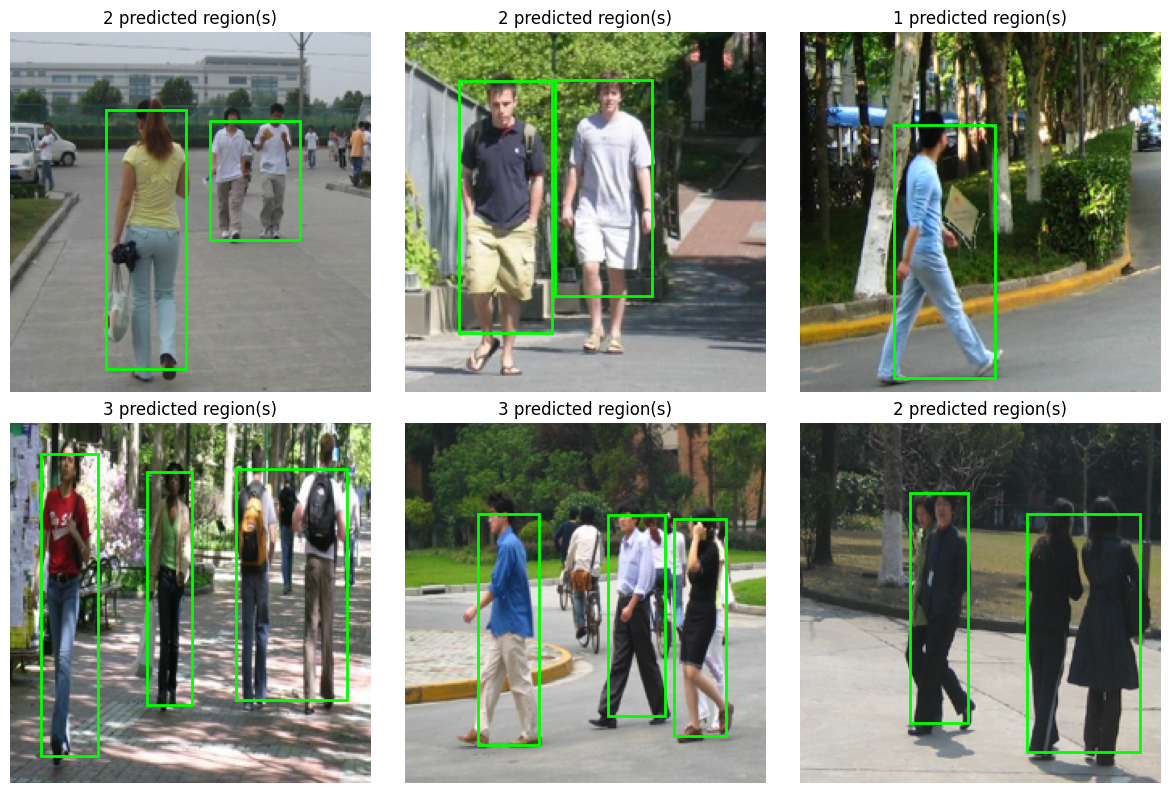

In [ ]:
from scipy import ndimage

def probs_to_boxes(prob, threshold=0.5, min_area=250):
    dense = F.interpolate(
        prob[None, None],
        size=(SIZE, SIZE),
        mode="bilinear",
        align_corners=False
    )[0, 0].cpu().numpy()

    dense = ndimage.gaussian_filter(dense, sigma=2)
    binary = dense >= threshold
    binary = ndimage.binary_closing(binary, iterations=3)
    binary = ndimage.binary_fill_holes(binary)

    components, n = ndimage.label(binary)
    boxes = []

    for region_id in range(1, n + 1):
        ys, xs = np.where(components == region_id)
        if len(xs) < min_area:
            continue

        x1, y1 = int(xs.min()), int(ys.min())
        x2, y2 = int(xs.max() + 1), int(ys.max() + 1)

        if (y2 - y1) < 20 or (x2 - x1) < 8:
            continue

        boxes.append([x1, y1, x2, y2])

    return boxes, binary

def denormalize(x):
    mean = torch.tensor(MEAN)[:, None, None]
    std = torch.tensor(STD)[:, None, None]
    return (x.cpu()*std+mean).clamp(0,1).permute(1,2,0).numpy()

from matplotlib.patches import Rectangle
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    image, _, target_mask = test_ped[i]
    boxes, mask = probs_to_boxes(probs[i], threshold=0.5)
    ax.imshow(denormalize(image))
    for x1, y1, x2, y2 in boxes:
        ax.add_patch(Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=2))
    ax.set_title(f'{len(boxes)} predicted region(s)'); ax.axis('off')
plt.tight_layout()
